# Balance de CO₂: etanol solo frente a crecimiento + etanol de Zenteno

Diagnóstico LAB016–021, **sin recalibrar**, sin modulación O₂, sin ganancia ajustada y sin simular el reservorio histórico.
Se revisan dos horizontes distintos: **0 → fin del registro** (¿cubre la fermentación completa?) y **entre muestras experimentales de etanol**,
además de tramos de 24 h y alrededor de la nutrición. Un registro cortado o con huecos no se llama fermentación completa.

Referencias: Zenteno et al. (2010), ecuaciones 14–16 y tabla 2 (`references/modeling/Zenteno_2010.pdf`).
La producción propuesta se compara con el gas emitido: su diferencia puede ser almacenamiento, error de cinética, conversión o medición;
no es automáticamente un error del modelo biológico.

No se generan CSV, PNG ni archivos adicionales en results. Todas las tablas y figuras quedan en este EXECUTED.

Se incorpora ahora el CO₂ disuelto de la muestra 1 medido con carbodoseur: LAB019 0.907, LAB020 0.730 y LAB021 0.829 g/L. LAB021 permanece **provisional** por extrapolación de la tabla.

In [1]:
from pathlib import Path
import sys,json,ast,hashlib,time
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/sources.csv').exists() and (p/'src').exists())
sys.dont_write_bytecode=True
sys.path.insert(0,str(ROOT/'src'))
from wine_fermentation import model as base
assert Path(sys.prefix).name.lower()=='fermentation'
CASES=('theta_full','theta_new','theta_nv2')
THETAS={name:base.normalize_parameters(json.loads((ROOT/f'configs/theta/{name}.json').read_text())) for name in CASES}
COLORS=dict(theta_full='#0072B2',theta_new='#D55E00',theta_nv2='#009E73')
plt.rcParams.update({'figure.dpi':110,'font.family':'DejaVu Sans','font.size':9})
pd.set_option('display.max_columns',30);pd.set_option('display.max_rows',100)
RHO=44.01/46.07;Y_E_CO2=1.05;Y_X_CO2=12.72
SETTINGS=dict(volume_liquid_L=2.,molar_volume_reference_L_mol=24.16,molar_mass_CO2_g_mol=44.0095,gas_correction=.74)
display(pd.Series(SETTINGS,name='Conversión histórica asumida, no calibración nueva'))
START=time.perf_counter()

volume_liquid_L                  2.0000
molar_volume_reference_L_mol    24.1600
molar_mass_CO2_g_mol            44.0095
gas_correction                   0.7400
Name: Conversión histórica asumida, no calibración nueva, dtype: float64

## Preparación y supuestos del sensor

Se usa `flow_sccm` de los registros originales copiados. Se conserva el reloj America/Santiago→UTC, incluida la transición de septiembre.
Las funciones de lectura, Hampel y filtros se copian aquí de la preparación revisada del ensayo anterior; no se ejecuta otro notebook.
El cero histórico se estima en 2.5–12 h: puede contener actividad biológica temprana y por ello se muestra también la sensibilidad sin restarlo.
Los huecos de hasta 60 s se interpolan; los mayores no se integran ni se rellenan con cero. La cobertura se informa siempre.

La conversión histórica es $q=Q_{sccm}M\,60\,0.74/(1000\,24.16\,2)$.
**2 L, 24.16 L/mol y 0.74 son supuestos heredados de la configuración GUI, no certificados del instrumento.**
Se contrasta con no aplicar 0.74 y con la otra conversión GUI de densidad 1.964 g/L.
Ninguna alternativa se selecciona buscando que cierre el balance. El área principal usa Hampel sin suavizado Butterworth;
los tres filtros se comparan como sensibilidad, nunca como ganancia de ajuste.

In [2]:
import ast

import json

from dataclasses import replace

from pathlib import Path

import numpy as np

import pandas as pd

from numpy.lib.stride_tricks import sliding_window_view

from scipy import signal

LABS = tuple(f"LAB{i:03}" for i in range(16, 22))

FILTERS = {"offline_20min": 1200., "offline_30min": 1800., "offline_40min": 2400.}

PRIMARY = "offline_30min"

OBS_STEP_H = 1. / 6.

LOD = .05

QUIET = .02

FACTOR = 44.0095 * 60. * .74 / (1000. * 24.16 * 2.)

LOCAL_ZONE = "America/Santiago"

def local_to_utc(values):
    """Interpret logger/worksheet civil times, rejecting ambiguous/invalid times."""
    return pd.DatetimeIndex(pd.to_datetime(values)).tz_localize(
        LOCAL_ZONE, ambiguous="raise", nonexistent="raise").tz_convert("UTC")

def elapsed_civil_hours(hours, origin_local):
    """Convert legacy naive-clock offsets, not actual elapsed durations, to UTC."""
    wall = origin_local + pd.to_timedelta(np.asarray(hours, float), unit="h")
    return (local_to_utc(wall)-local_to_utc([origin_local])[0]).total_seconds()/3600.

def centered_hampel(values, dt_s, window_s=120., k=3.5, floor=.5):
    """Exact median/MAD of the same centered odd window, reflection at edges."""
    x = np.asarray(values, float)
    assert np.isfinite(x).all()
    half = max(1, int(round(window_s / (2. * dt_s))))
    padded = np.pad(x, (half, half), mode="reflect")
    windows = sliding_window_view(padded, 2 * half + 1)
    med = np.median(windows, axis=1)
    mad = np.median(abs(windows - med[:, None]), axis=1)
    flag = abs(x-med) > np.maximum(k * 1.4826 * mad, floor)
    return np.where(flag, med, x), flag

def runs(mask):
    edges = np.diff(np.r_[False, np.asarray(mask, bool), False].astype(int))
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))

def fill_short_gaps(series, max_samples):
    result = series.copy()
    candidate = series.interpolate(method="time", limit_area="inside")
    for a, b in runs(series.isna().to_numpy()):
        if b-a <= max_samples and a > 0 and b < len(series):
            result.iloc[a:b] = candidate.iloc[a:b]
    return result

def butter_sos(tau_s, dt_s, order=3):
    cutoff = 1. / (2. * np.pi * tau_s)
    return signal.butter(order, cutoff, fs=1. / dt_s, output="sos")

def zero_phase(values, tau_s, dt_s):
    # The default SciPy padding is too short for this very low cutoff.
    padlen = min(int(np.ceil(6. * tau_s / dt_s)), len(values)-2)
    assert padlen > 12 and len(values) > 24
    return signal.sosfiltfilt(butter_sos(tau_s, dt_s), values, padtype="odd", padlen=padlen)

def read_window(path, root, columns, start, end=None):
    content = Path(path)
    pieces = []
    for chunk in pd.read_csv(content, usecols=columns, chunksize=400000, low_memory=False):
        stamp = pd.to_datetime(chunk.timestamp, errors="coerce")
        keep = stamp.ge(start)
        if end is not None:
            keep &= stamp.le(end)
        if keep.any():
            part = chunk.loc[keep].copy()
            part["timestamp"] = stamp[keep]
            pieces.append(part)
    if not pieces:
        raise ValueError(f"No data in requested window: {path}")
    return pd.concat(pieces, ignore_index=True), content

class DiagnosticInputs:
    def __init__(self, root):
        self.root=Path(root)
        self.v2=self.root/'data/compatibility/co2_v3'
        settings=json.loads((self.root/'configs/co2_v3_reference.json').read_text(encoding='utf-8'))
        self.gui=settings['gui']
        assert self.gui==dict(W_SPIKE_SECONDS=120.,K=3.5,MIN_ABS_SPIKE=.5,TAU_SECONDS=1200.,BUTTER_ORDER=3)
        self.initials=pd.read_csv(self.v2/'initial_conditions_v2.csv').set_index('lab')
        self.chem=pd.read_csv(self.v2/'chemistry_v2.csv')
        self.density=pd.read_csv(self.v2/'density_v2.csv')
        self.biomass=pd.read_csv(self.v2/'biomass_v2.csv')
        self.previous_chemistry=pd.DataFrame(columns=['lab','t_h'])
        self.v2_initials=self.initials.copy()
        self.raw_co2,self.raw_temperature,self.t0,self.artifacts={},{},{},{}
        self.dense,self.temperature,self.observations={},{},{}
        self.filter_audit,self.coverage_rows,self.temp_audit=[],[],[]
        self.clock_audit,self.elapsed_audit,self.nutrition_events=[],[],[]
        old_dir=self.root/'data/original/natural/lab016_018'
        book_path=old_dir/'LAB016-018-offline-measurements.xlsx'
        sheet=pd.read_excel(book_path,sheet_name='CondicionesIniciales').set_index('CodigoLab')
        recent_dir=self.root/'data/original/natural/lab019_021'
        recent_t0=pd.Timestamp('2026-09-21 17:00:00')
        recent_co2,_=read_window(recent_dir/'backup_global_co2_completo.csv',self.root,
            ['timestamp','fermentador','flow_sccm','flow_filt_sccm','status'],recent_t0-pd.Timedelta(hours=6))
        recent_temp,_=read_window(recent_dir/'backup_global_temperatura_completo.csv',self.root,
            ['timestamp','fermentador','T','SP','nutricion_activa'],recent_t0-pd.Timedelta(hours=6))
        for i, lab in enumerate(LABS):
            fermenter = f"F{i%3+1}"
            if i < 3:
                row = sheet.loc[lab]
                clock = row.Hora if hasattr(row.Hora, "hour") else pd.to_datetime(str(row.Hora)).time()
                t0 = pd.Timestamp.combine(pd.Timestamp(row.Fecha).date(), clock)
                raw_path = old_dir/f"CO2_F{i+1}_{lab}.csv"
                filt_path = old_dir/f"CO2_FILT_F{i+1}_{lab}.csv"
                temp_path = old_dir/({0:"Temp_F1_LAB016.csv",1:"Temp_F2_LAB017.csv",2:"Temp_F3._LAB018.csv"}[i])
                raw = pd.read_csv(raw_path, parse_dates=["timestamp"])
                recorded = pd.read_csv(filt_path, parse_dates=["timestamp"])
                raw = raw.merge(recorded[["timestamp", "flow_filt_sccm"]], on="timestamp", how="left", validate="one_to_one")
                tmp = pd.read_csv(temp_path, parse_dates=["timestamp"])
            else:
                t0 = recent_t0
                raw = recent_co2[recent_co2.fermentador.eq(fermenter)].copy()
                tmp = recent_temp[recent_temp.fermentador.eq(fermenter)].copy()
            origin_local = t0
            t0 = local_to_utc([origin_local])[0]
            for kind, frame in (("co2", raw), ("temperature", tmp)):
                wall = pd.DatetimeIndex(frame.timestamp)
                utc = local_to_utc(wall)
                local_dt = wall.to_series(index=np.arange(len(wall))).diff().dt.total_seconds().to_numpy()
                real_dt = utc.to_series(index=np.arange(len(utc))).diff().dt.total_seconds().to_numpy()
                jumps = np.flatnonzero(abs(local_dt-real_dt)>1.)
                for j in jumps:
                    self.clock_audit.append(dict(lab=lab,signal=kind,
                        previous_local=str(wall[j-1]),next_local=str(wall[j]),
                        previous_utc=str(utc[j-1]),next_utc=str(utc[j]),
                        civil_interval_seconds=float(local_dt[j]),elapsed_interval_seconds=float(real_dt[j])))
                frame["timestamp_local"] = frame.timestamp.astype(str)
                frame["timestamp"] = utc
            raw = raw[raw.timestamp.ge(t0-pd.Timedelta(hours=6))].sort_values("timestamp").copy()
            tmp = tmp[tmp.timestamp.ge(t0-pd.Timedelta(hours=6))].sort_values("timestamp").copy()
            assert raw.timestamp.is_unique and tmp.timestamp.is_unique
            raw["t_h"] = (raw.timestamp-t0).dt.total_seconds()/3600.
            tmp["t_h"] = (tmp.timestamp-t0).dt.total_seconds()/3600.
            self.t0[lab], self.raw_co2[lab], self.raw_temperature[lab] = t0, raw, tmp
            # Pump activation is nutrition, not evidence of a measurement artifact.
            # Keep its measured response; no bridges, recovery windows or guards.
            self.artifacts[lab] = []
            state = pd.to_numeric(tmp.nutricion_activa, errors="raise").eq(1)
            for a,b in runs(state):
                self.nutrition_events.append(dict(lab=lab,start_h=float(tmp.t_h.iloc[a]),
                    end_h=float(tmp.t_h.iloc[min(b,len(tmp)-1)]),excluded_from_fit=False))
            for name, frame in (("chemistry",self.chem),("density",self.density),
                                ("biomass",self.biomass),("previous_chemistry",self.previous_chemistry)):
                ids = frame.index[frame.lab.eq(lab)]
                if not len(ids):continue
                # t_h=0 may intentionally map a pre-inoculation sample to the
                # initial condition. Preserve that mapping and the measurement.
                old = frame.loc[ids,"t_h"].to_numpy(float)
                if name == "previous_chemistry":
                    # The legacy simulation includes artificial civil-clock
                    # grid points inside the skipped hour; they are not samples.
                    wall = origin_local+pd.to_timedelta(old,unit="h")
                    utc = pd.DatetimeIndex(wall).tz_localize(LOCAL_ZONE,
                        ambiguous="raise",nonexistent="NaT").tz_convert("UTC")
                    exists = ~utc.isna()
                    frame.drop(index=ids[~exists],inplace=True)
                    ids,old,utc = ids[exists],old[exists],utc[exists]
                    new = (utc-t0).total_seconds()/3600.
                else:
                    new = elapsed_civil_hours(old,origin_local)
                frame.loc[ids,"t_h"] = new
                for idx,before,after in zip(ids,old,new):
                    self.elapsed_audit.append(dict(lab=lab,table=name,row=int(idx),
                        civil_t_h=float(before),elapsed_t_h=float(after)))
            old_events = ast.literal_eval(self.initials.loc[lab,"N_events"])
            corrected_events = tuple((float(elapsed_civil_hours([h],origin_local)[0]),dose) for h,dose in old_events)
            self.initials.loc[lab,"N_events"] = repr(corrected_events)
            self.initials.loc[lab,"horizon_h"] = float(elapsed_civil_hours(
                [self.v2_initials.loc[lab,"horizon_h"]],origin_local)[0])

    def _process_temperature(self, lab):
        raw = self.raw_temperature[lab]
        minute = raw.set_index("timestamp")[["T", "SP"]].resample("1min").median()
        minute["T"] = fill_short_gaps(minute["T"], 2)
        result = pd.DataFrame(index=minute.index)
        result["raw_1min"] = minute["T"]
        for name, med, mean in (("reference_20_45", "20min", "45min"), ("strong_30_60", "30min", "60min")):
            result[name] = np.nan
            for a,b in runs(minute["T"].notna()):
                segment = minute["T"].iloc[a:b]
                filtered = segment.rolling(med,center=True,min_periods=1).median().rolling(mean,center=True,min_periods=1).mean()
                result.iloc[a:b,result.columns.get_loc(name)] = filtered.to_numpy()
            valid = result[name].notna() & result.raw_1min.notna()
            self.temp_audit.append(dict(lab=lab,variant=name,raw_std_C=float(result.loc[valid,"raw_1min"].std()),
                filtered_std_C=float(result.loc[valid,name].std()),mean_change_C=float((result.loc[valid,name]-result.loc[valid,"raw_1min"]).mean()),
                max_change_C=float(abs(result.loc[valid,name]-result.loc[valid,"raw_1min"]).max())))
        result["SP"] = minute.SP
        result["time_h"] = (result.index-self.t0[lab]).total_seconds()/3600.
        self.temperature[lab] = result

    def _process_co2(self, lab):
        raw = self.raw_co2[lab]
        dt = float(raw.timestamp.diff().dt.total_seconds().median())
        assert 5. <= dt <= 30., (lab,dt)
        series = raw.set_index("timestamp")[["flow_sccm", "flow_filt_sccm"]].resample(pd.Timedelta(seconds=dt)).median()
        series.index += pd.Timedelta(seconds=dt/2.)
        series["flow_sccm"] = fill_short_gaps(series.flow_sccm, int(60./dt))
        time = (series.index-self.t0[lab]).total_seconds().to_numpy()/3600.
        clean = series.flow_sccm.copy()
        frame = pd.DataFrame(dict(time_h=time,raw_sccm=series.flow_sccm.to_numpy(),
            recorded_sccm=series.flow_filt_sccm.to_numpy(),clean_sccm=clean.to_numpy()),index=series.index)
        frame["despiked_sccm"],frame["hampel_spike"] = np.nan,False
        blocks = [(a,b) for a,b in runs(clean.notna()) if b-a > 100]
        for name in FILTERS:
            frame[name] = np.nan
        for a,b in blocks:
            despiked, flag = centered_hampel(clean.iloc[a:b].to_numpy(), dt)
            frame.iloc[a:b,frame.columns.get_loc("despiked_sccm")] = despiked
            frame.iloc[a:b,frame.columns.get_loc("hampel_spike")] = flag
            for name,tau in FILTERS.items():
                frame.iloc[a:b,frame.columns.get_loc(name)] = zero_phase(despiked,tau,dt)
        # One sensor-zero estimate, from the same raw-derived despiked baseline,
        # is shared by every smoothing variant. Nothing is subtracted from chemistry.
        baseline = (time >= 2.5) & (time <= 12.) & frame.despiked_sccm.notna().to_numpy()
        for event in self.artifacts[lab]:
            baseline &= ~((time >= event["start_h"]) & (time <= event["end_h"]))
        assert baseline.sum() > 20, lab
        zero = max(0.,float(frame.loc[baseline,"despiked_sccm"].quantile(.1)))
        self.fit_exclusions = getattr(self,"fit_exclusions",{})
        # Padding is a numerical extension only, never a fit exclusion margin.
        guard = 0.
        exclusions = []
        self.fit_exclusions[lab] = exclusions
        valid = frame[PRIMARY].notna().to_numpy()
        for name,tau in FILTERS.items():
            uncorrected = frame[name].to_numpy().copy()
            frame[name] = np.maximum(uncorrected-zero,0.)*FACTOR
            use = valid & (time >= 0.)
            peak = int(np.nanargmax(np.where(use,frame[name],np.nan)))
            self.filter_audit.append(dict(lab=lab,variant=name,tau_s=tau,order=3,passes=2,
                raw_dt_s=dt,zero_sccm=zero,n_raw=len(raw),n_grid=len(frame),
                n_hampel=int(frame.hampel_spike.sum()),n_fit_dense=int(use.sum()),
                peak_g_l_h=float(frame[name].iloc[peak]),peak_h=float(time[peak]),
                negative_before_clipping_fraction=float(np.nanmean(uncorrected < zero)),
                data_start_h=float(time[0]),data_end_h=float(time[-1]),guard_h=guard))
        frame["despiked"] = np.maximum(frame.despiked_sccm-zero,0.)*FACTOR
        frame["recorded"] = np.maximum(frame.recorded_sccm-float(pd.read_csv(self.v2/"sensor_audit.csv").set_index("lab").loc[lab,"zero_sccm"]),0.)*FACTOR
        frame["valid_for_fit"] = valid
        self.dense[lab] = frame
        self.filter_blocks = getattr(self,"filter_blocks",{})
        self.filter_blocks[lab] = (dt, blocks)

In [3]:
D=DiagnosticInputs(ROOT)
for lab in LABS:
    D._process_temperature(lab);D._process_co2(lab)
assert np.isclose(FACTOR,SETTINGS['molar_mass_CO2_g_mol']*60*SETTINGS['gas_correction']/(1000*SETTINGS['molar_volume_reference_L_mol']*SETTINGS['volume_liquid_L']))
conversion_audit=pd.DataFrame(D.filter_audit)
print('Datos preparados en',round(time.perf_counter()-START,1),'s; saltos de reloj detectados:',len(D.clock_audit))
display(pd.DataFrame(D.clock_audit))
def area(t,y,a,b):
    """Trapezoids on finite adjacent samples, clipped exactly to [a,b]; no long-gap bridges."""
    t=np.asarray(t,float);y=np.asarray(y,float)
    dt=np.diff(t);left=np.maximum(t[:-1],a);right=np.minimum(t[1:],b)
    typical=float(np.median(dt))
    valid=np.isfinite(y[:-1])&np.isfinite(y[1:])&(dt<=max(typical*2.5,1e-6))&(right>left)
    i=np.flatnonzero(valid)
    ya=y[i]+(y[i+1]-y[i])*(left[i]-t[i])/dt[i]
    yb=y[i]+(y[i+1]-y[i])*(right[i]-t[i])/dt[i]
    return float(np.sum(.5*(ya+yb)*(right[i]-left[i]))),float(np.sum(right[i]-left[i]))
def integral(t,y,a,b):return area(t,y,a,b)[0]
def cumulative(t,y):
    t=np.asarray(t);y=np.asarray(y)
    ok=np.isfinite(y[:-1])&np.isfinite(y[1:])&(np.diff(t)<=2.5*np.median(np.diff(t)))
    return np.r_[0.,np.cumsum(np.where(ok,.5*(np.nan_to_num(y[:-1])+np.nan_to_num(y[1:]))*np.diff(t),0.))]
# Meaningful numerical checks: analytic area with non-grid endpoints, and missing-data exclusion.
assert np.allclose(area([0,1,2],[0,1,2],.25,1.75),(1.5,1.5))
assert np.allclose(area([0,1,2,3,4],[1,1,np.nan,1,1],0,4),(2.,2.))
coverage_rows=[];ENDS={};GAS={}
for lab in LABS:
    frame=D.dense[lab].copy();t=frame.time_h.to_numpy();y=frame.despiked.to_numpy()
    end=float(t[np.isfinite(y)&(t>=0)][-1]);ENDS[lab]=end
    GAS[lab]=dict(t=t,primary=y,filtered=frame[PRIMARY].to_numpy(),no_zero=np.maximum(frame.despiked_sccm.to_numpy(),0)*FACTOR)
    amount,covered=area(t,y,0,end)
    tail,tail_covered=area(t,y,max(0,end-2),end)
    chem=D.chem[D.chem.lab.eq(lab)&~D.chem.is_NUT&~D.chem.is_initial].dropna(subset=['E_g_l'])
    coverage_rows.append(dict(lab=lab,first_gas_h=float(t[np.isfinite(y)&(t>=0)][0]),last_gas_h=end,
        covered_fraction=covered/end,missing_h=end-covered,CO2_observed_g_l=amount,
        tail_mean_g_l_h=tail/tail_covered if tail_covered else np.nan,tail_quiet=tail_covered>=1.99 and tail/tail_covered<=QUIET,
        n_measured_ethanol_post_initial=len(chem),last_measured_E_h=float(chem.t_h.max()) if len(chem) else np.nan))
COVERAGE=pd.DataFrame(coverage_rows)
display(COVERAGE.round(5));display(conversion_audit.query('variant == @PRIMARY')[['lab','zero_sccm','n_hampel','data_start_h','data_end_h']].round(5))
display(Markdown('**Fin de registro no equivale a fin de fermentación.** La cola baja es un criterio operativo, no prueba de agotamiento químico. Una integral con huecos es cantidad observada parcial, sin extrapolación.'))

Datos preparados en 14.4 s; saltos de reloj detectados: 6


,lab,signal,previous_local,next_local,previous_utc,next_utc,civil_interval_seconds,elapsed_interval_seconds
0,LAB016,co2,2026-09-05 23:59:47,2026-09-06 01:00:01,2026-09-06 03:59:47+00:00,2026-09-06 04:00:01+00:00,3614.0,14.0
1,LAB016,temperature,2026-09-05 23:59:59,2026-09-06 01:00:13,2026-09-06 03:59:59+00:00,2026-09-06 04:00:13+00:00,3614.0,14.0
2,LAB017,co2,2026-09-05 23:59:47,2026-09-06 01:00:01,2026-09-06 03:59:47+00:00,2026-09-06 04:00:01+00:00,3614.0,14.0
3,LAB017,temperature,2026-09-05 23:59:46,2026-09-06 01:00:00,2026-09-06 03:59:46+00:00,2026-09-06 04:00:00+00:00,3614.0,14.0
4,LAB018,co2,2026-09-05 23:59:47,2026-09-06 01:00:01,2026-09-06 03:59:47+00:00,2026-09-06 04:00:01+00:00,3614.0,14.0
5,LAB018,temperature,2026-09-05 23:59:47,2026-09-06 01:00:01,2026-09-06 03:59:47+00:00,2026-09-06 04:00:01+00:00,3614.0,14.0


,lab,first_gas_h,last_gas_h,covered_fraction,missing_h,CO2_observed_g_l,tail_mean_g_l_h,tail_quiet,n_measured_ethanol_post_initial,last_measured_E_h
0,LAB016,0.00153,151.10181,1.0,0.0,48.15113,0.03413,False,0,NaN
1,LAB017,0.00014,151.10042,1.0,0.0,53.04791,0.01533,True,0,NaN
2,LAB018,0.00125,151.09847,1.0,0.0,49.10913,0.01674,True,0,NaN
3,LAB019,0.00139,183.08194,1.0,0.0,38.57077,0.00653,True,5,166.0
4,LAB020,0.00139,183.08194,1.0,0.0,33.31492,0.01685,True,5,166.0
5,LAB021,0.00139,183.08194,1.0,0.0,37.29329,0.00481,True,5,166.0


,lab,zero_sccm,n_hampel,data_start_h,data_end_h
1,LAB016,0.0,220,-5.99958,151.10181
4,LAB017,0.0,260,-5.99792,151.10042
7,LAB018,0.0,226,-5.99986,151.09847
10,LAB019,0.0,177,-5.14583,183.08194
13,LAB020,0.0,156,-5.14861,183.08194
16,LAB021,0.0,238,-5.14861,183.08194


**Fin de registro no equivale a fin de fermentación.** La cola baja es un criterio operativo, no prueba de agotamiento químico. Una integral con huecos es cantidad observada parcial, sin extrapolación.

## Tres referencias de producción, separando lo experimental de lo calculado

1. **Etanol solo, estequiometría:** $P_E=0.955285\,\Delta E$.
2. **Etanol solo, coeficiente de Zenteno:** $P_{E,Z}=\Delta E/1.05$.
3. **Zenteno completo:** $P_Z=\Delta E/1.05+B/12.72$, con $B=\int\mu X\,dt$.

Mostrar 1 y 2 evita confundir el pequeño cambio de coeficiente con el efecto del crecimiento.
Para la corrección de crecimiento usamos el modelo químico actual: no contamos $\Delta X_{viable}$ como crecimiento bruto.
Su balance de N permite calcular exactamente $B=Y_{X/N}[N_0+N_{añadido}-N(t)]$, sin estado muerto ni cuadratura de una discontinuidad.
En la comparación con etanol medido, solo B depende del theta: **la referencia completa pasa a ser híbrida, no enteramente experimental**.
Los rendimientos CO₂ de Zenteno son referencias de literatura; su coherencia con los rendimientos químicos calibrados aún debe evaluarse.

In [4]:
CORES={};PROD={};model_checks=[]
for lab in LABS:
    temperature=D.temperature[lab].dropna(subset=['reference_20_45'])
    end=min(ENDS[lab],float(temperature.time_h.max()));end=max(end,0.)
    events=ast.literal_eval(D.initials.loc[lab,'N_events'])
    grid=np.unique(np.r_[np.arange(0,end,1/12),end,[t for t,_ in events if 0<=t<=end]])
    initial=D.v2_initials.loc[lab]
    batch=base.BatchData('natural',lab,grid,np.interp(grid,temperature.time_h,temperature.reference_20_45),
        {'N':events},{s:np.full(len(grid),np.nan) for s in base.STATE_NAMES},{s:float(initial[s]) for s in base.STATE_NAMES})
    for name,theta in THETAS.items():
        core=base.integrate(batch,theta);dose=np.array([sum(d for t,d in events if t<ti) for ti in grid])
        B=theta['Yxn']*(initial.N+dose-core.N.to_numpy())
        assert np.min(B)>-1e-6 and np.min(np.diff(B))>-1e-6
        B=np.maximum(B,0.)
        growth_rate=np.array([base.kinetic_terms(theta,temp,*row)['mu']*row[0] for temp,row in zip(batch.temperature_c,core.to_numpy())])
        eflux=np.array([(base.kinetic_terms(theta,temp,*row)['beta_g']+base.kinetic_terms(theta,temp,*row)['beta_f'])*row[0] for temp,row in zip(batch.temperature_c,core.to_numpy())])
        pE=(core.E.to_numpy()-initial.E)/Y_E_CO2;pG=B/Y_X_CO2
        pred=pd.DataFrame(dict(t_h=grid,E_only_stoich=RHO*(core.E-initial.E),E_only_zenteno=pE,growth=pG,zenteno=pE+pG,
            rate_E=eflux/Y_E_CO2,rate_Z=eflux/Y_E_CO2+growth_rate/Y_X_CO2))
        CORES[name,lab]=core;PROD[name,lab]=pred
        model_checks.append(dict(theta=name,lab=lab,gross_growth_g_l=B[-1],CO2_growth_g_l=pG[-1],
            fraction_growth=float(pG[-1]/max((pE+pG)[-1],1e-12)),min_state=float(core.min().min()),jump_error=core.attrs['jump_error']))
CHECKS=pd.DataFrame(model_checks)
display(CHECKS.round(6))
print('Fuentes biológicas calculadas; sin ajuste de parámetros, O2, reservorio ni matrix_gain.')

,theta,lab,gross_growth_g_l,CO2_growth_g_l,fraction_growth,min_state,jump_error
0,theta_full,LAB016,1.323300,0.104033,0.001389,0.0,0.0
1,theta_new,LAB016,1.827083,0.143639,0.001910,0.0,0.0
2,theta_nv2,LAB016,1.835393,0.144292,0.001906,0.0,0.0
3,theta_full,LAB017,1.846151,0.145138,0.001947,0.0,0.0
4,theta_new,LAB017,2.548985,0.200392,0.002684,0.0,0.0
5,theta_nv2,LAB017,2.560579,0.201303,0.002675,0.0,0.0
6,theta_full,LAB018,1.323300,0.104033,0.001389,0.0,0.0
7,theta_new,LAB018,1.827083,0.143639,0.001910,0.0,0.0
8,theta_nv2,LAB018,1.835393,0.144292,0.001905,0.0,0.0
9,theta_full,LAB019,1.157836,0.091025,0.001347,0.0,0.0


Fuentes biológicas calculadas; sin ajuste de parámetros, O2, reservorio ni matrix_gain.


## Horizonte desde inoculación y localización por tramos

La integración de gas comienza en t=0 y llega al final disponible. Las comparaciones con el modelo usan el mismo soporte observado,
excluyendo los huecos de ambas integrales. Por ello la tabla distingue duración solicitada de duración realmente comparada.
Se muestran ventanas completas, de 24 h y pre/post nutrición. La diferencia producción−emisión es almacenamiento requerido **más**
posibles errores de cinética, conversión y medición; sin Cd medido no se atribuye íntegramente al depósito disuelto.

In [5]:
windows=[];sensitivity=[]
for lab in LABS:
    t=GAS[lab]['t'];y=GAS[lab]['primary'];end=min(ENDS[lab],float(PROD['theta_nv2',lab].t_h.max()))
    events=ast.literal_eval(D.initials.loc[lab,'N_events']);first=min(e[0] for e in events)
    intervals=[('0_fin_registro',0.,end)]
    intervals += [('24h',float(a),float(min(a+24,end))) for a in np.arange(0,end,24)]
    intervals += [('pre_nutricion',0.,first),('0_24h_post_nutricion',first,min(first+24,end)),('tardio',min(first+24,end),end)]
    for label,a,b in intervals:
        if b<=a:continue
        observed,covered=area(t,y,a,b)
        for name in CASES:
            pred=PROD[name,lab];cumE=np.interp(t,pred.t_h,pred.E_only_zenteno);cumG=np.interp(t,pred.t_h,pred.growth)
            # Exact model cumulative increments over exactly the valid sensor segments.
            dt=np.diff(t);left=np.maximum(t[:-1],a);right=np.minimum(t[1:],b)
            ok=np.isfinite(y[:-1])&np.isfinite(y[1:])&(dt<=2.5*np.median(dt))&(right>left)
            P_E=float(np.sum(np.interp(right[ok],pred.t_h,pred.E_only_zenteno)-np.interp(left[ok],pred.t_h,pred.E_only_zenteno)))
            P_G=float(np.sum(np.interp(right[ok],pred.t_h,pred.growth)-np.interp(left[ok],pred.t_h,pred.growth)))
            windows.append(dict(lab=lab,theta=name,window=label,start_h=a,end_h=b,coverage=covered/(b-a),
                gas_observed_g_l=observed,E_only_g_l=P_E,growth_g_l=P_G,zenteno_g_l=P_E+P_G,
                delta_E_only=P_E-observed,delta_zenteno=P_E+P_G-observed))
    for channel in ('primary','filtered','no_zero'):
        value,cov=area(t,GAS[lab][channel],0,end)
        sensitivity.append(dict(lab=lab,scenario=channel,area_g_l=value,covered_h=cov))
    base_area,cov=area(t,y,0,end)
    sensitivity += [dict(lab=lab,scenario='sin_factor_0.74',area_g_l=base_area/.74,covered_h=cov),
        dict(lab=lab,scenario='otra_GUI_densidad_1.964',area_g_l=base_area*(1.964/(44.0095/24.16*.74)),covered_h=cov)]
WINDOWS=pd.DataFrame(windows);SENSITIVITY=pd.DataFrame(sensitivity)
display(WINDOWS.query('window == "0_fin_registro"').round(4))
display(WINDOWS.query('theta == "theta_nv2" and window != "0_fin_registro"').round(4))
display(SENSITIVITY.pivot(index='lab',columns='scenario',values='area_g_l').round(4))

,lab,theta,window,start_h,end_h,coverage,gas_observed_g_l,E_only_g_l,growth_g_l,zenteno_g_l,delta_E_only,delta_zenteno
0,LAB016,theta_full,0_fin_registro,0.0,151.0847,1.0,48.1496,74.7907,0.1040,74.8947,26.6411,26.7452
1,LAB016,theta_new,0_fin_registro,0.0,151.0847,1.0,48.1496,75.0564,0.1436,75.2000,26.9068,27.0504
2,LAB016,theta_nv2,0_fin_registro,0.0,151.0847,1.0,48.1496,75.5782,0.1443,75.7225,27.4286,27.5729
33,LAB017,theta_full,0_fin_registro,0.0,151.0833,1.0,53.0478,74.4113,0.1451,74.5564,21.3635,21.5086
34,LAB017,theta_new,0_fin_registro,0.0,151.0833,1.0,53.0478,74.4638,0.2004,74.6642,21.4160,21.6164
35,LAB017,theta_nv2,0_fin_registro,0.0,151.0833,1.0,53.0478,75.0567,0.2013,75.2580,22.0089,22.2102
66,LAB018,theta_full,0_fin_registro,0.0,151.0814,1.0,49.1088,74.7871,0.1040,74.8911,25.6783,25.7823
67,LAB018,theta_new,0_fin_registro,0.0,151.0814,1.0,49.1088,75.0598,0.1436,75.2034,25.9510,26.0946
68,LAB018,theta_nv2,0_fin_registro,0.0,151.0814,1.0,49.1088,75.5842,0.1443,75.7285,26.4754,26.6197
99,LAB019,theta_full,0_fin_registro,0.0,183.0819,1.0,38.5708,67.4947,0.0910,67.5857,28.9239,29.0149


,lab,theta,window,start_h,end_h,coverage,gas_observed_g_l,E_only_g_l,growth_g_l,zenteno_g_l,delta_E_only,delta_zenteno
5,LAB016,theta_nv2,24h,0.0000,24.0000,1.0,0.9922,9.3310,0.0594,9.3904,8.3388,8.3982
8,LAB016,theta_nv2,24h,24.0000,48.0000,1.0,12.5956,18.4210,0.0279,18.4489,5.8254,5.8533
11,LAB016,theta_nv2,24h,48.0000,72.0000,1.0,15.7617,21.4522,0.0570,21.5092,5.6904,5.7474
14,LAB016,theta_nv2,24h,72.0000,96.0000,1.0,10.6874,18.0355,0.0000,18.0355,7.3480,7.3480
17,LAB016,theta_nv2,24h,96.0000,120.0000,1.0,5.5111,6.3803,0.0000,6.3803,0.8692,0.8692
20,LAB016,theta_nv2,24h,120.0000,144.0000,1.0,2.3525,1.8314,0.0000,1.8314,-0.5212,-0.5212
23,LAB016,theta_nv2,24h,144.0000,151.0847,1.0,0.2490,0.1270,0.0000,0.1270,-0.1220,-0.1220
26,LAB016,theta_nv2,pre_nutricion,0.0000,56.9356,1.0,19.6127,34.6221,0.0873,34.7094,15.0095,15.0967
29,LAB016,theta_nv2,0_24h_post_nutricion,56.9356,80.9356,1.0,14.4294,23.1907,0.0570,23.2477,8.7613,8.8184
32,LAB016,theta_nv2,tardio,80.9356,151.0847,1.0,14.1075,17.7654,0.0000,17.7654,3.6578,3.6578


scenario,filtered,no_zero,otra_GUI_densidad_1.964,primary,sin_factor_0.74
lab,,,,,
LAB016,48.2304,48.1496,70.1540,48.1496,65.0670
LAB017,53.0820,53.0478,77.2908,53.0478,71.6862
LAB018,49.1488,49.1088,71.5517,49.1088,66.3633
LAB019,38.5617,38.5708,56.1977,38.5708,52.1227
LAB020,33.3135,33.3149,48.5399,33.3149,45.0202
LAB021,37.2712,37.2933,54.3364,37.2933,50.3963


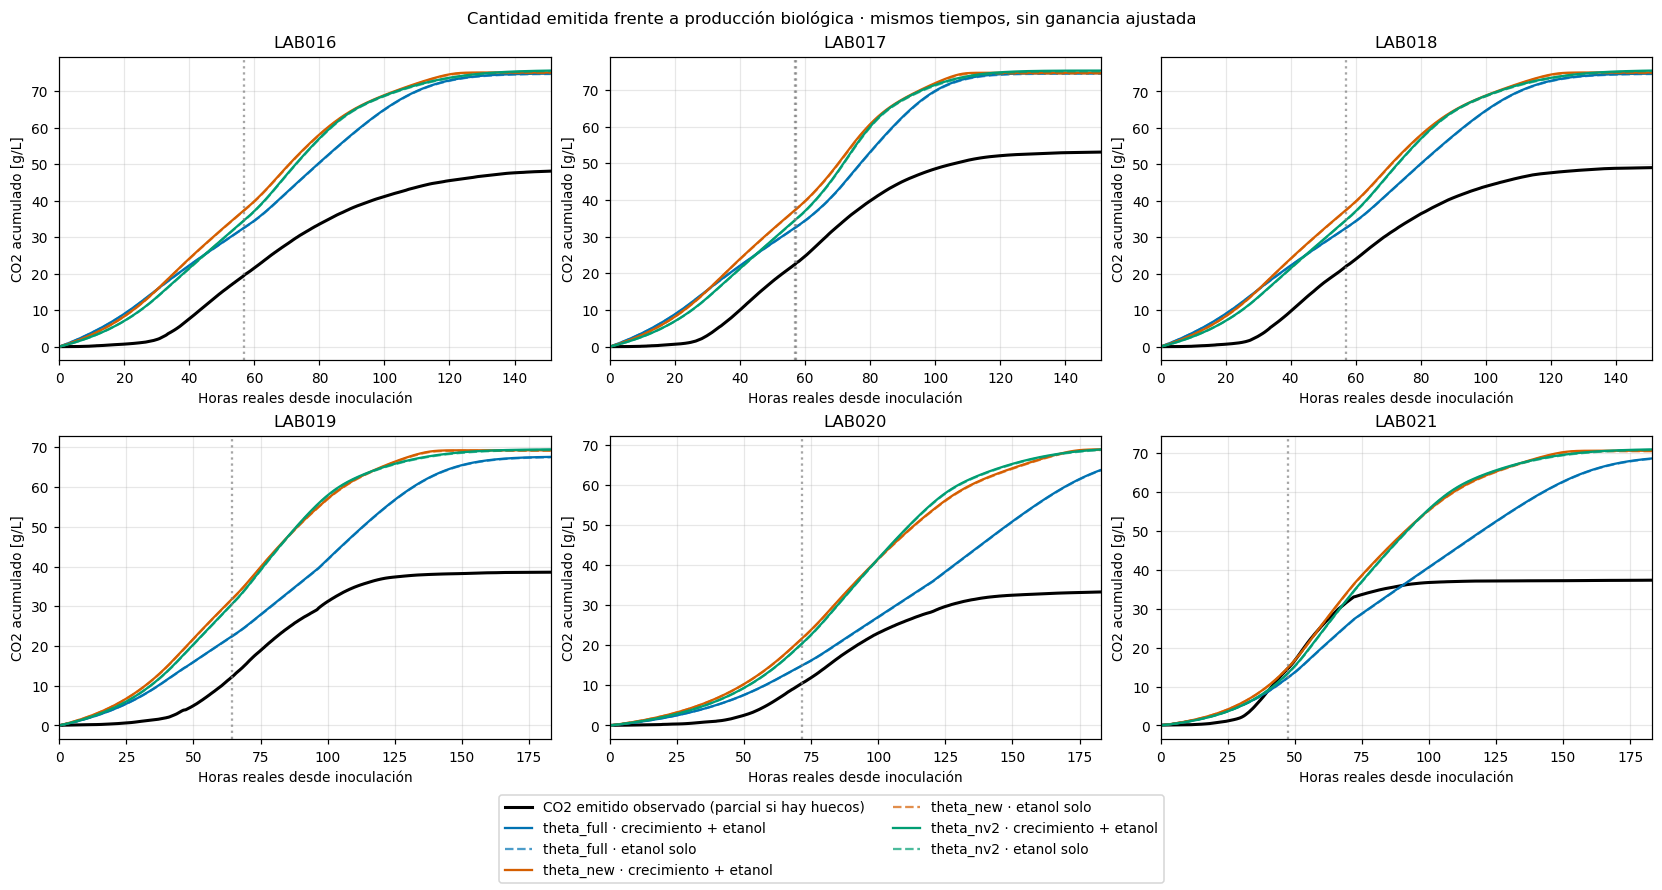

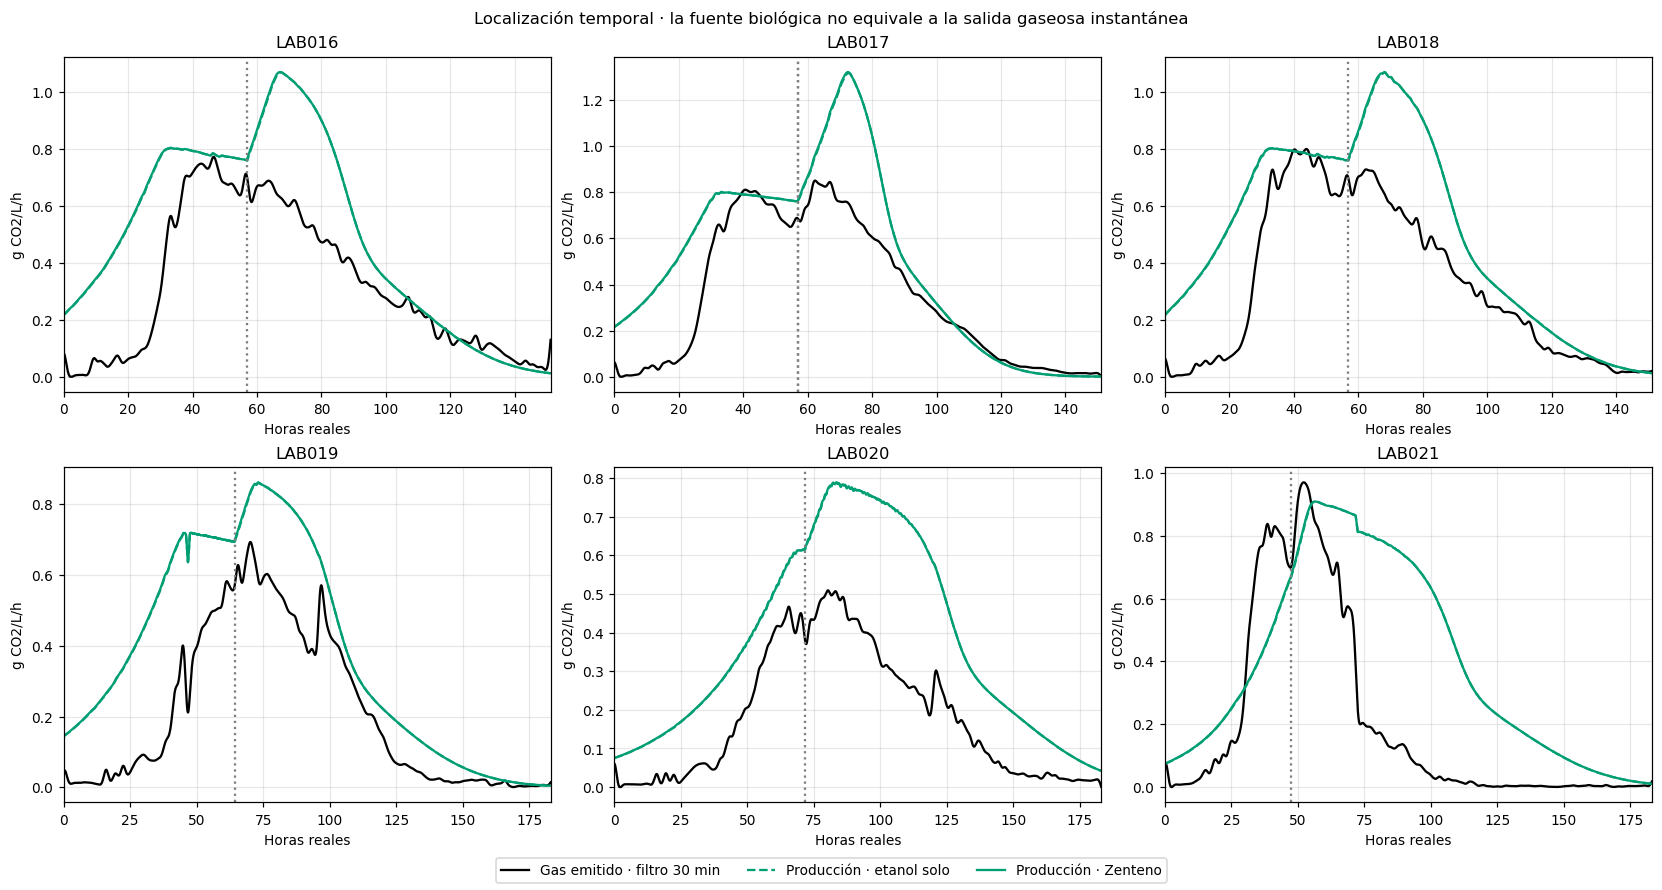

In [6]:
fig,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for ax,lab in zip(axes.flat,LABS):
    t=GAS[lab]['t'];mask=t>=0
    observed=cumulative(t[mask],GAS[lab]['primary'][mask])
    ax.plot(t[mask],observed,color='black',lw=2,label='CO2 emitido observado (parcial si hay huecos)')
    for name in CASES:
        p=PROD[name,lab]
        ax.plot(p.t_h,p.zenteno,color=COLORS[name],label=name+' · crecimiento + etanol')
        ax.plot(p.t_h,p.E_only_zenteno,color=COLORS[name],ls='--',alpha=.7,label=name+' · etanol solo')
    for event,_ in ast.literal_eval(D.initials.loc[lab,'N_events']):ax.axvline(event,c='gray',ls=':',alpha=.7)
    ax.set_title(lab);ax.set_xlabel('Horas reales desde inoculación');ax.set_ylabel('CO2 acumulado [g/L]');ax.grid(alpha=.3)
    ax.set_xlim(0,ENDS[lab])
handles,labels=axes.flat[0].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=2)
fig.suptitle('Cantidad emitida frente a producción biológica · mismos tiempos, sin ganancia ajustada')
plt.show()
fig,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for ax,lab in zip(axes.flat,LABS):
    t=GAS[lab]['t'];y=GAS[lab]['primary'];keep=t>=0
    ax.plot(t[keep],GAS[lab]['filtered'][keep],c='black',label='Gas emitido · filtro 30 min')
    p=PROD['theta_nv2',lab]
    ax.plot(p.t_h,p.rate_E,ls='--',c=COLORS['theta_nv2'],label='Producción · etanol solo')
    ax.plot(p.t_h,p.rate_Z,c=COLORS['theta_nv2'],label='Producción · Zenteno')
    for event,_ in ast.literal_eval(D.initials.loc[lab,'N_events']):ax.axvline(event,c='gray',ls=':')
    ax.set_title(lab);ax.set_xlabel('Horas reales');ax.set_ylabel('g CO2/L/h');ax.set_xlim(0,ENDS[lab]);ax.grid(alpha=.3)
handles,labels=axes.flat[0].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=3)
fig.suptitle('Localización temporal · la fuente biológica no equivale a la salida gaseosa instantánea')
plt.show()

## Comparación independiente con etanol experimental

Se usan muestras Y15 con E finito, excluyendo NUT de horario provisional. Las muestras m1 se conservan como **proxy inicial**,
no como mediciones realizadas en la inoculación: fueron tomadas antes de ella y se mapearon a t=0 en las entradas anteriores.
La tabla muestra tanto primera→última muestra **posterior** a inoculación como m1→última y los intervalos consecutivos.
Cada comparación indica cobertura. Una muestra final fuera del registro de gas no se extrapola.

Con etanol medido, la referencia etanol-solo es independiente de theta; Zenteno completo añade B del modelo.
El cambio de inventario requerido es $\Delta C_d=P-CO2_{emitido}$; incluye todos los errores de ambas referencias.
Un aumento negativo del etanol se marca y no se corrige artificialmente.
LAB016–018 no tiene series de etanol en la tabla química copiada; sus comparaciones son solo dependientes del modelo.

El CO₂ inicial de la muestra 1 se aplica al balance desde t=0. No se suma directamente a los intervalos que comienzan en 22 h: el inventario disuelto a las 22 h es distinto y no está medido.

,lab,sample,used_h,actual_extraction_h,E_g_l,initial_proxy,X_total,X_viable
0,LAB019,1,0.0,-1.1667,12.0754,True,0.8595,0.8295
1,LAB019,4,22.0,22.0000,13.7328,False,0.4377,0.4285
2,LAB019,7,46.0,46.0000,18.2314,False,1.6314,1.6268
3,LAB019,10,70.5,70.5000,33.0692,False,1.8663,1.8616
4,LAB019,11,87.5,87.5000,48.3804,False,1.1037,1.0806
5,LAB019,12,166.0,166.0000,78.2137,False,NaN,NaN
6,LAB020,1,0.0,-1.1667,11.9175,True,0.4113,0.4067
7,LAB020,4,22.0,22.0000,9.5498,False,0.4863,0.4782
8,LAB020,7,46.0,46.0000,18.5471,False,1.0506,1.0390
9,LAB020,10,70.5,70.5000,29.5965,False,1.7211,1.7049


,lab,window,start_h,end_h,initial_proxy,delta_E_g_l,coverage,comparison_covered,gas_observed_g_l,ethanol_only_stoich,ethanol_only_Z,negative_delta_E,growth_theta_full,Z_theta_full,growth_theta_new,Z_theta_new,growth_theta_nv2,Z_theta_nv2,required_delta_Cd_ethanol,required_delta_Cd_Z_nv2
0,LAB019,primera_ultima_muestra_real,22.0,166.0,False,64.4809,1.0,True,38.0078,61.5977,61.4104,False,0.0637,61.4741,0.0961,61.5065,0.0967,61.5071,23.5899,23.4993
1,LAB019,proxy_t0_ultima,0.0,166.0,True,66.1383,1.0,True,38.4929,63.1810,62.9889,False,0.0910,63.0799,0.1257,63.1145,0.1262,63.1151,24.6880,24.6222
7,LAB020,primera_ultima_muestra_real,22.0,166.0,False,69.3383,1.0,True,32.6860,66.2379,66.0365,False,0.0779,66.1143,0.1111,66.1476,0.1117,66.1482,33.5519,33.4622
8,LAB020,proxy_t0_ultima,0.0,166.0,True,66.9706,1.0,True,32.9871,63.9760,63.7815,False,0.0897,63.8712,0.1239,63.9054,0.1244,63.9060,30.9889,30.9188
14,LAB021,primera_ultima_muestra_real,22.0,166.0,False,63.6310,1.0,True,36.4217,60.7857,60.6009,False,0.0725,60.6735,0.1057,60.7066,0.1063,60.7072,24.3640,24.2855
15,LAB021,proxy_t0_ultima,0.0,166.0,True,67.1036,1.0,True,37.2334,64.1031,63.9082,False,0.0914,63.9996,0.1262,64.0344,0.1267,64.0349,26.8697,26.8015


,lab,window,start_h,end_h,initial_proxy,delta_E_g_l,coverage,comparison_covered,gas_observed_g_l,ethanol_only_stoich,ethanol_only_Z,negative_delta_E,growth_theta_full,Z_theta_full,growth_theta_new,Z_theta_new,growth_theta_nv2,Z_theta_nv2,required_delta_Cd_ethanol,required_delta_Cd_Z_nv2
2,LAB019,consecutivas,0.0,22.0,True,1.6574,1.0,True,0.4851,1.5833,1.5785,False,0.0274,1.6058,0.0296,1.6081,0.0295,1.6080,1.0982,1.1229
3,LAB019,consecutivas,22.0,46.0,False,4.4987,1.0,True,3.2951,4.2975,4.2844,False,0.0402,4.3246,0.0632,4.3476,0.0637,4.3481,1.0024,1.0530
4,LAB019,consecutivas,46.0,70.5,False,14.8377,1.0,True,12.3038,14.1743,14.1312,False,0.0194,14.1506,0.0269,14.1580,0.0271,14.1582,1.8704,1.8544
5,LAB019,consecutivas,70.5,87.5,False,15.3113,1.0,True,9.5829,14.6266,14.5821,False,0.0040,14.5862,0.0060,14.5882,0.0059,14.5881,5.0437,5.0052
6,LAB019,consecutivas,87.5,166.0,False,29.8333,1.0,True,12.8259,28.4993,28.4126,False,0.0000,28.4126,0.0000,28.4126,0.0000,28.4126,15.6734,15.5868
9,LAB020,consecutivas,0.0,22.0,True,-2.3677,1.0,True,0.3012,-2.2618,-2.2550,True,0.0119,-2.2431,0.0128,-2.2422,0.0127,-2.2422,-2.5630,-2.5434
10,LAB020,consecutivas,22.0,46.0,False,8.9973,1.0,True,1.5049,8.5950,8.5689,False,0.0261,8.5950,0.0294,8.5983,0.0293,8.5982,7.0901,7.0933
11,LAB020,consecutivas,46.0,70.5,False,11.0494,1.0,True,8.3020,10.5553,10.5232,False,0.0283,10.5515,0.0491,10.5723,0.0497,10.5729,2.2533,2.2709
12,LAB020,consecutivas,70.5,87.5,False,10.5758,1.0,True,7.9037,10.1029,10.0722,False,0.0235,10.0957,0.0326,10.1048,0.0327,10.1049,2.1993,2.2012
13,LAB020,consecutivas,87.5,166.0,False,38.7158,1.0,True,14.9753,36.9846,36.8722,False,0.0000,36.8722,0.0000,36.8722,0.0000,36.8722,22.0093,21.8969


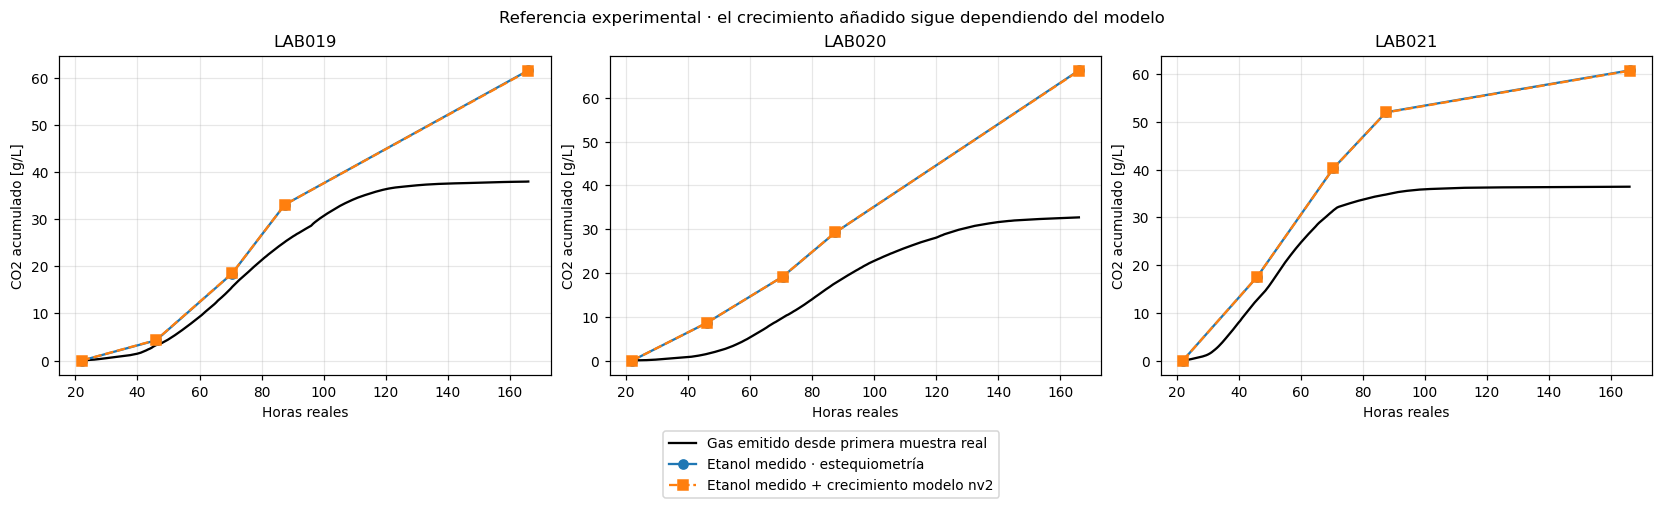

In [7]:
measured=[];sample_rows=[]
for lab in LABS:
    samples=D.chem[D.chem.lab.eq(lab)&~D.chem.is_NUT].dropna(subset=['E_g_l']).sort_values('t_h').copy()
    if len(samples)==0:continue
    raw_t0=D.t0[lab]
    for row in samples.itertuples():
        actual_t=float((local_to_utc([row.sample_timestamp])[0]-raw_t0).total_seconds()/3600.)
        sample_rows.append(dict(lab=lab,sample=row.sample,used_h=row.t_h,actual_extraction_h=actual_t,E_g_l=row.E_g_l,
            initial_proxy=bool(row.is_initial),X_total=row.X_total_g_l,X_viable=row.X_viable_g_l))
    selections=[];post=samples[~samples.is_initial & samples.t_h.gt(0)]
    if len(post)>=2:selections.append(('primera_ultima_muestra_real',post.iloc[0],post.iloc[-1]))
    if len(samples)>=2:selections.append(('proxy_t0_ultima',samples.iloc[0],samples.iloc[-1]))
    selections += [('consecutivas',samples.iloc[i],samples.iloc[i+1]) for i in range(len(samples)-1)]
    for label,r0,r1 in selections:
        a,b=float(r0.t_h),float(r1.t_h)
        if b<=a:continue
        emitted,covered=area(GAS[lab]['t'],GAS[lab]['primary'],a,b)
        coverage=covered/(b-a);dE=float(r1.E_g_l-r0.E_g_l)
        complete=coverage>=.995 and b<=ENDS[lab]+1e-6 and a>=0
        row=dict(lab=lab,window=label,start_h=a,end_h=b,initial_proxy=bool(r0.is_initial),delta_E_g_l=dE,
            coverage=coverage,comparison_covered=complete,gas_observed_g_l=emitted,ethanol_only_stoich=RHO*dE,
            ethanol_only_Z=dE/Y_E_CO2,negative_delta_E=dE<0)
        for name in CASES:
            p=PROD[name,lab]
            supported=a>=p.t_h.min() and b<=p.t_h.max()+1e-6
            growth=float(np.interp(b,p.t_h,p.growth)-np.interp(a,p.t_h,p.growth)) if supported else np.nan
            row['growth_'+name]=growth;row['Z_'+name]=dE/Y_E_CO2+growth
        row['required_delta_Cd_ethanol']=RHO*dE-emitted if complete else np.nan
        row['required_delta_Cd_Z_nv2']=row['Z_theta_nv2']-emitted if complete else np.nan
        measured.append(row)
SAMPLES=pd.DataFrame(sample_rows);EXPERIMENTAL=pd.DataFrame(measured)
display(SAMPLES.round(4))
display(EXPERIMENTAL.query('window != "consecutivas"').round(4))
display(EXPERIMENTAL.query('window == "consecutivas"').round(4))
fig,axes=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
for ax,lab in zip(axes,LABS[3:]):
    samples=SAMPLES[SAMPLES.lab.eq(lab)&~SAMPLES.initial_proxy].sort_values('used_h')
    if len(samples)<2:continue
    a=float(samples.used_h.iloc[0]);E0=float(samples.E_g_l.iloc[0]);t=GAS[lab]['t'];y=GAS[lab]['primary']
    x=np.linspace(a,float(samples.used_h.iloc[-1]),250)
    ax.plot(x,[integral(t,y,a,b) for b in x],c='black',label='Gas emitido desde primera muestra real')
    ax.plot(samples.used_h,RHO*(samples.E_g_l-E0),'o-',label='Etanol medido · estequiometría')
    p=PROD['theta_nv2',lab];growth=np.interp(samples.used_h,p.t_h,p.growth)-np.interp(a,p.t_h,p.growth)
    ax.plot(samples.used_h,(samples.E_g_l-E0)/Y_E_CO2+growth,'s--',label='Etanol medido + crecimiento modelo nv2')
    ax.set_title(lab);ax.set_xlabel('Horas reales');ax.set_ylabel('CO2 acumulado [g/L]');ax.grid(alpha=.3)
handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=1)
fig.suptitle('Referencia experimental · el crecimiento añadido sigue dependiendo del modelo')
plt.show()

## Balance incorporando el CO₂ disuelto inicial del carbodoseur

Se usan las temperaturas del log **indicadas por el usuario**, no las temperaturas offline:

| LAB | Volumen residual [mL] | Temperatura [°C] | Cd(0) [g/L] | Estado |
|---|---:|---:|---:|---|
| LAB019 | 85 | 18 | 0.907 | Lectura directa de tabla |
| LAB020 | 90 | 16 | 0.730 | Lectura directa de tabla |
| LAB021 | 85 | 21 | 0.829 | **Provisional**: extrapolación lineal desde 19–20 °C |

Fuente: `data/Tabla_CO2_disuelto_carbodoseur_long.csv` y lecturas/temperaturas confirmadas por el usuario.
La tabla termina en 20 °C; el valor de LAB021 no se convierte en definitivo por incorporarlo al cálculo.
La muestra 1 fue tomada antes de inoculación y se adopta como proxy de la condición inicial, igual que su etanol.

El balance para volumen aproximadamente constante, sin pérdidas no medidas, es:

\[
G(t)=P(t)+C_d(0)-C_d(t),\qquad
\boxed{C_{d,\mathrm{requerido}}(t)=C_d(0)+P(t)-G(t)}.
\]

G es el gas registrado acumulado desde t=0. Se evalúan P por etanol experimental solo (estequiometría y coeficiente de Zenteno)
y P de Zenteno completo (etanol experimental más crecimiento calculado con cada theta).
**Cd final no está medido: no hay una única predicción del gas emitido a partir de P y Cd inicial.**
También se muestra el escenario condicional Cd final=0: entonces G=P+Cd inicial; no se adopta como hecho ni se ajusta para cerrar el balance.

Si el inventario requerido resulta negativo, se conserva y se marca: no es una concentración física ni se recorta a cero.
Indica incompatibilidad del balance simplificado con esa combinación de observaciones/supuestos, que puede involucrar
variación de volumen, pérdidas de etanol o gas e incertidumbre analítica o de conversión.


,volume_residual_mL,temperature_C,Cd0_g_l,provisional
lab,,,,
LAB019,85,18,0.907,False
LAB020,90,16,0.73,False
LAB021,85,21,0.829,True


,lab,time_h,provisional,Cd0_g_l,coverage,gas_observed_g_l,production_ethanol,production_Z_theta_nv2,gas_if_final_Cd_zero,required_Cd_ethanol,required_Cd_Z_theta_nv2
0,LAB019,166.0,False,0.907,1.0,38.4929,63.1810,63.1151,64.0880,25.5950,25.5292
1,LAB020,166.0,False,0.730,1.0,32.9871,63.9760,63.9060,64.7060,31.7189,31.6488
2,LAB021,166.0,True,0.829,1.0,37.2334,64.1031,64.0349,64.9321,27.6987,27.6305


,lab,sample,time_h,provisional,coverage,gas_observed_g_l,production_ethanol,required_Cd_ethanol,required_Cd_Z_theta_nv2,negative_inventory
0,LAB019,1,0.0,False,1.0,0.0000,0.0000,0.9070,0.9070,False
1,LAB019,4,22.0,False,1.0,0.4851,1.5833,2.0052,2.0299,False
2,LAB019,7,46.0,False,1.0,3.7803,5.8808,3.0075,3.0829,False
3,LAB019,10,70.5,False,1.0,16.0841,20.0551,4.8779,4.9373,False
4,LAB019,11,87.5,False,1.0,25.6670,34.6817,9.9216,9.9424,False
5,LAB019,12,166.0,False,1.0,38.4929,63.1810,25.5950,25.5292,False
6,LAB020,1,0.0,False,1.0,0.0000,0.0000,0.7300,0.7300,False
7,LAB020,4,22.0,False,1.0,0.3012,-2.2618,-1.8330,-1.8134,True
8,LAB020,7,46.0,False,1.0,1.8061,6.3332,5.2571,5.2799,False
9,LAB020,10,70.5,False,1.0,10.1081,16.8885,7.5104,7.5507,False


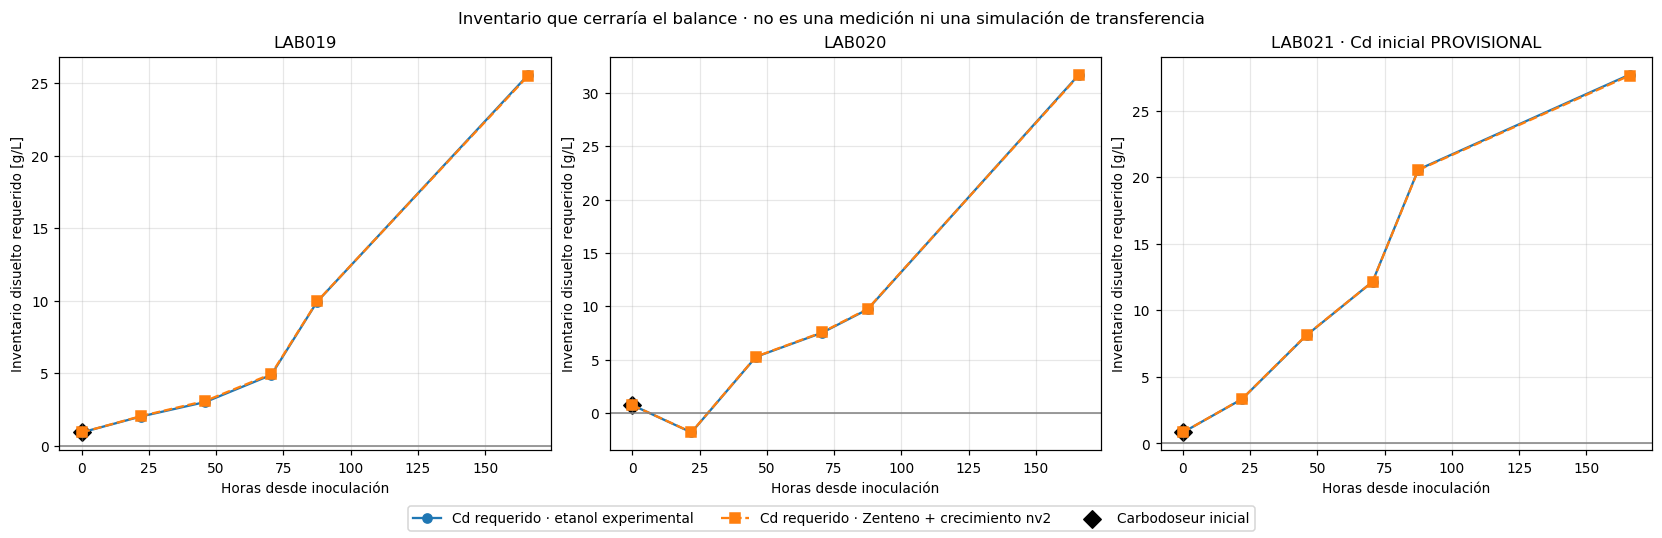

**Resultado:** al incluir el inventario inicial, el CO₂ disuelto final requerido sigue siendo de decenas de g/L y aumenta en 0.907, 0.730 y 0.829 g/L respecto al cálculo sin inventario inicial. El depósito inicial no explica por sí solo el déficit acumulado. El valor de LAB021 y todo cálculo que lo utiliza permanecen provisionales. No se ha supuesto una concentración final medida ni reajustado una ganancia.

In [8]:

INITIAL_DISSOLVED={
    'LAB019':dict(volume_residual_mL=85,temperature_C=18,Cd0_g_l=.907,provisional=False),
    'LAB020':dict(volume_residual_mL=90,temperature_C=16,Cd0_g_l=.730,provisional=False),
    'LAB021':dict(volume_residual_mL=85,temperature_C=21,Cd0_g_l=.829,provisional=True),
}
conversion_table=pd.read_csv(ROOT/'data/Tabla_CO2_disuelto_carbodoseur_long.csv')
def table_co2(volume,temp):
    selected=conversion_table[(conversion_table.volumen_residual_mL==volume)&(conversion_table.temperatura_C==temp)]
    assert len(selected)==1
    return float(selected.CO2_mg_L.iloc[0])/1000.
assert np.isclose(INITIAL_DISSOLVED['LAB019']['Cd0_g_l'],table_co2(85,18))
assert np.isclose(INITIAL_DISSOLVED['LAB020']['Cd0_g_l'],table_co2(90,16))
assert not ((conversion_table.volumen_residual_mL==85)&(conversion_table.temperatura_C==21)).any()
assert np.isclose(INITIAL_DISSOLVED['LAB021']['Cd0_g_l'],table_co2(85,20)+(table_co2(85,20)-table_co2(85,19)))
display(pd.DataFrame(INITIAL_DISSOLVED).T.rename_axis('lab'))
initial_inventory_rows=[];initial_inventory_summary=[]
for lab,setting in INITIAL_DISSOLVED.items():
    samples=SAMPLES[SAMPLES.lab.eq(lab)].sort_values('used_h')
    initial_sample=samples[samples.initial_proxy].iloc[0]
    initial_E=float(initial_sample.E_g_l);cd0=setting['Cd0_g_l']
    for sample in samples.itertuples():
        b=float(sample.used_h)
        emitted,covered=area(GAS[lab]['t'],GAS[lab]['primary'],0.,b)
        covered_fraction=covered/b if b>0 else 1.
        valid=covered_fraction>=.995 and b<=ENDS[lab]+1e-6
        p_ethanol=RHO*(float(sample.E_g_l)-initial_E)
        p_zenteno_E=(float(sample.E_g_l)-initial_E)/Y_E_CO2
        row=dict(lab=lab,sample=sample.sample,time_h=b,initial_proxy=sample.initial_proxy,
            provisional=setting['provisional'],Cd0_g_l=cd0,coverage=covered_fraction,
            gas_observed_g_l=emitted,production_ethanol=p_ethanol,production_Z_ethanol=p_zenteno_E,
            required_Cd_ethanol=cd0+p_ethanol-emitted if valid else np.nan,
            gas_if_final_Cd_zero=p_ethanol+cd0,
            negative_inventory=(cd0+p_ethanol-emitted < -1e-8) if valid else None)
        for name in CASES:
            pred=PROD[name,lab]
            growth=float(np.interp(b,pred.t_h,pred.growth)-np.interp(0.,pred.t_h,pred.growth)) if b<=pred.t_h.max()+1e-6 else np.nan
            row['production_Z_'+name]=p_zenteno_E+growth
            row['required_Cd_Z_'+name]=cd0+p_zenteno_E+growth-emitted if valid else np.nan
        initial_inventory_rows.append(row)
    last=initial_inventory_rows[-1]
    initial_inventory_summary.append({k:last[k] for k in ('lab','time_h','provisional','Cd0_g_l','coverage',
        'gas_observed_g_l','production_ethanol','production_Z_theta_nv2','gas_if_final_Cd_zero',
        'required_Cd_ethanol','required_Cd_Z_theta_nv2')})
INITIAL_BALANCE=pd.DataFrame(initial_inventory_rows)
INITIAL_BALANCE_SUMMARY=pd.DataFrame(initial_inventory_summary)
display(INITIAL_BALANCE_SUMMARY.round(4))
display(INITIAL_BALANCE[['lab','sample','time_h','provisional','coverage','gas_observed_g_l','production_ethanol',
    'required_Cd_ethanol','required_Cd_Z_theta_nv2','negative_inventory']].round(4))
fig,axes=plt.subplots(1,3,figsize=(15,4.8),layout='constrained')
for ax,lab in zip(axes,INITIAL_DISSOLVED):
    rows=INITIAL_BALANCE[INITIAL_BALANCE.lab.eq(lab)]
    ax.plot(rows.time_h,rows.required_Cd_ethanol,'o-',label='Cd requerido · etanol experimental')
    ax.plot(rows.time_h,rows.required_Cd_Z_theta_nv2,'s--',label='Cd requerido · Zenteno + crecimiento nv2')
    ax.scatter([0],[INITIAL_DISSOLVED[lab]['Cd0_g_l']],marker='D',s=65,c='black',label='Carbodoseur inicial')
    ax.axhline(0,c='gray',lw=1)
    ax.set_title(lab+(' · Cd inicial PROVISIONAL' if INITIAL_DISSOLVED[lab]['provisional'] else ''))
    ax.set_xlabel('Horas desde inoculación');ax.set_ylabel('Inventario disuelto requerido [g/L]');ax.grid(alpha=.3)
handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=3)
fig.suptitle('Inventario que cerraría el balance · no es una medición ni una simulación de transferencia')
plt.show()
# Checks: at t0 the reconstruction returns the adopted measurement; the correction shifts by +Cd0.
for lab,setting in INITIAL_DISSOLVED.items():
    first=INITIAL_BALANCE[(INITIAL_BALANCE.lab==lab)&INITIAL_BALANCE.initial_proxy].iloc[0]
    assert np.isclose(first.required_Cd_ethanol,setting['Cd0_g_l'])
    previous=EXPERIMENTAL[(EXPERIMENTAL.lab==lab)&(EXPERIMENTAL.window=='proxy_t0_ultima')].iloc[0]
    last=INITIAL_BALANCE_SUMMARY[INITIAL_BALANCE_SUMMARY.lab==lab].iloc[0]
    assert np.isclose(last.required_Cd_ethanol-previous.required_delta_Cd_ethanol,setting['Cd0_g_l'])
assert bool(INITIAL_BALANCE_SUMMARY[INITIAL_BALANCE_SUMMARY.lab=='LAB021'].provisional.iloc[0])
display(Markdown('**Resultado:** al incluir el inventario inicial, el CO₂ disuelto final requerido sigue siendo de '
    'decenas de g/L y aumenta en 0.907, 0.730 y 0.829 g/L respecto al cálculo sin inventario inicial. '
    'El depósito inicial no explica por sí solo el déficit acumulado. El valor de LAB021 y todo cálculo que lo utiliza '
    'permanecen provisionales. No se ha supuesto una concentración final medida ni reajustado una ganancia.'))


## Lectura de resultados y límites

Los tramos permiten localizar discordancias, no asignarles automáticamente una causa. Ni producción≈emisión instantánea ni una gran
diferencia acumulada prueban por sí solas el mecanismo. Primero se revisan cobertura, conversión, muestras iniciales y coherencia química.
La acumulación disuelta solo puede explicar un inventario finito; no se introduce una ganancia libre para ocultar un déficit.
La comparación no utiliza ni calibra O2, transportadores o un nuevo modelo de transferencia.

,lab,interval_h,coverage,gas_observed,expected_ethanol,expected_Z_nv2,added_growth_nv2,required_delta_inventory
0,LAB019,22.00–166.00,1.0,38.0078,61.5977,61.5071,0.0967,23.4993
1,LAB020,22.00–166.00,1.0,32.6860,66.2379,66.1482,0.1117,33.4622
2,LAB021,22.00–166.00,1.0,36.4217,60.7857,60.7072,0.1063,24.2855


La mayor contribución de crecimiento calculada en los seis LAB y tres theta es **0.201 g CO₂/L**. Su importancia debe compararse con las diferencias de las tablas, no suponerse de antemano. Las configuraciones de conversión son hipótesis documentadas: cambiar entre ellas requiere revisar instrumento y volumen real.

Diagnóstico completo, sin optimización ni exportaciones externas. Tiempo: 29.6 s


,lab,start_h,end_h,coverage,gas_observed_g_l,zenteno_g_l,delta_zenteno
5,LAB016,0.0,24.0,1.0,0.9922,9.3904,8.3982
38,LAB017,0.0,24.0,1.0,1.0354,9.2222,8.1868
71,LAB018,0.0,24.0,1.0,1.0222,9.3704,8.3482
107,LAB019,24.0,48.0,1.0,3.6640,13.2915,9.6275
152,LAB020,96.0,120.0,1.0,6.7590,16.6401,9.8811
185,LAB021,72.0,96.0,1.0,3.4918,18.3736,14.8818


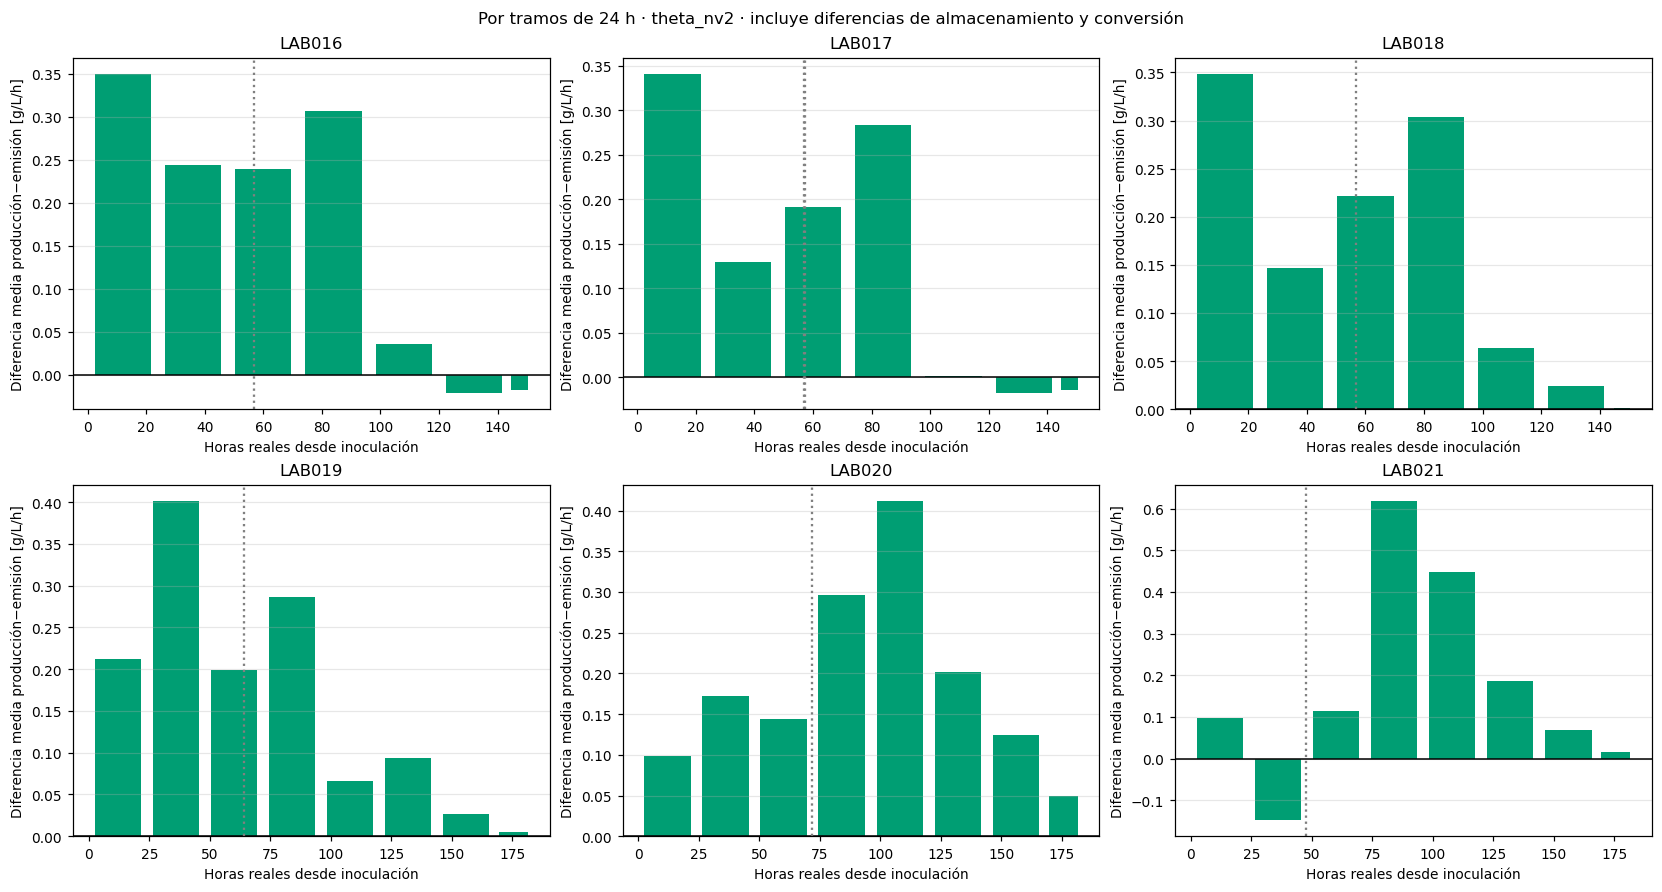

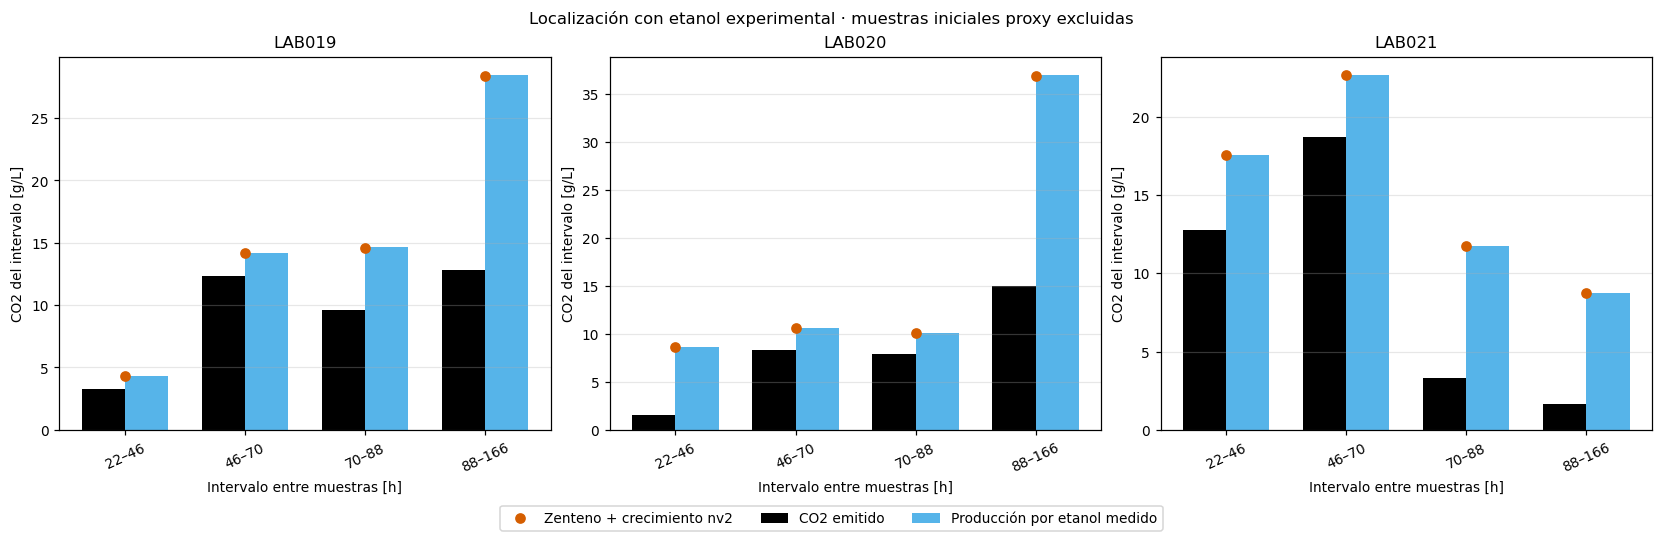

**Hallazgo del balance:** en el intervalo de muestras reales 22–166 h, la diferencia entre producción por etanol y gas emitido es de decenas de g/L bajo la conversión histórica. El aporte de crecimiento de Zenteno es del orden de décimas de g/L y no resuelve esa diferencia. La discrepancia aumenta especialmente en el último intervalo muestreado. Esto orienta a revisar volumen real, unidades y calibración del caudalímetro, integridad del circuito de gas y coherencia del análisis de etanol; no identifica por sí solo cuál es la causa. Un mejor ajuste de forma mediante una ganancia no cierra este balance físico.

La tabla siguiente es una **equivalencia condicional**: supone almacenamiento neto despreciable y una única causa. No estima ni sustituye el volumen ni la calibración reales; no se utiliza para corregir curvas.

,lab,assumed_volume_L,assumed_gas_correction,volume_if_only_volume_explains_difference,correction_if_only_gas_factor_explains_difference
0,LAB019,2.0,0.74,1.2341,1.1993
1,LAB020,2.0,0.74,0.9869,1.4996
2,LAB021,2.0,0.74,1.1984,1.2350


In [9]:
summary=[]
for lab in LABS[3:]:
    rows=EXPERIMENTAL[(EXPERIMENTAL.lab==lab)&(EXPERIMENTAL.window=='primera_ultima_muestra_real')]
    if len(rows):
        r=rows.iloc[0]
        summary.append(dict(lab=lab,interval_h=f'{r.start_h:.2f}–{r.end_h:.2f}',coverage=r.coverage,
            gas_observed=r.gas_observed_g_l,expected_ethanol=r.ethanol_only_stoich,expected_Z_nv2=r.Z_theta_nv2,
            added_growth_nv2=r.growth_theta_nv2,required_delta_inventory=r.required_delta_Cd_Z_nv2))
display(pd.DataFrame(summary).round(4))
max_growth=float(CHECKS.CO2_growth_g_l.max())
display(Markdown(f'La mayor contribución de crecimiento calculada en los seis LAB y tres theta es **{max_growth:.3f} g CO₂/L**. '
    'Su importancia debe compararse con las diferencias de las tablas, no suponerse de antemano. '
    'Las configuraciones de conversión son hipótesis documentadas: cambiar entre ellas requiere revisar instrumento y volumen real.'))
assert all(float(x)>=0 for x in COVERAGE.CO2_observed_g_l)
assert len(CHECKS)==18
assert all(abs(x)<1e-12 for x in CHECKS.jump_error)
print('Diagnóstico completo, sin optimización ni exportaciones externas. Tiempo:',round(time.perf_counter()-START,1),'s')

# Locate the largest disagreements without calling source-vs-emission differences kinetic errors.
blocks=WINDOWS.query('theta == "theta_nv2" and window == "24h"').copy()
blocks['mean_difference_g_l_h']=blocks.delta_zenteno/((blocks.end_h-blocks.start_h)*blocks.coverage)
display(blocks.loc[blocks.groupby('lab').delta_zenteno.idxmax(),
    ['lab','start_h','end_h','coverage','gas_observed_g_l','zenteno_g_l','delta_zenteno']].round(4))
fig,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for ax,lab in zip(axes.flat,LABS):
    b=blocks[blocks.lab.eq(lab)]
    ax.bar((b.start_h+b.end_h)/2,b.mean_difference_g_l_h,width=(b.end_h-b.start_h)*.8,color=COLORS['theta_nv2'])
    ax.axhline(0,c='black',lw=1)
    for event,_ in ast.literal_eval(D.initials.loc[lab,'N_events']):ax.axvline(event,c='gray',ls=':')
    ax.set_title(lab);ax.set_xlabel('Horas reales desde inoculación');ax.set_ylabel('Diferencia media producción−emisión [g/L/h]');ax.grid(axis='y',alpha=.3)
fig.suptitle('Por tramos de 24 h · theta_nv2 · incluye diferencias de almacenamiento y conversión')
plt.show()

fig,axes=plt.subplots(1,3,figsize=(15,4.8),layout='constrained')
for ax,lab in zip(axes,LABS[3:]):
    b=EXPERIMENTAL.query('lab == @lab and window == "consecutivas" and initial_proxy == False').copy()
    x=np.arange(len(b));labels=[f'{a:.0f}–{z:.0f}' for a,z in zip(b.start_h,b.end_h)]
    ax.bar(x-.18,b.gas_observed_g_l,width=.36,color='black',label='CO2 emitido')
    ax.bar(x+.18,b.ethanol_only_stoich,width=.36,color='#56B4E9',label='Producción por etanol medido')
    ax.plot(x,b.Z_theta_nv2,'o',c='#D55E00',label='Zenteno + crecimiento nv2')
    ax.set_xticks(x,labels,rotation=25);ax.set_title(lab);ax.set_xlabel('Intervalo entre muestras [h]');ax.set_ylabel('CO2 del intervalo [g/L]');ax.grid(axis='y',alpha=.3)
handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=3)
fig.suptitle('Localización con etanol experimental · muestras iniciales proxy excluidas')
plt.show()

display(Markdown('**Hallazgo del balance:** en el intervalo de muestras reales 22–166 h, la diferencia entre '
    'producción por etanol y gas emitido es de decenas de g/L bajo la conversión histórica. '
    'El aporte de crecimiento de Zenteno es del orden de décimas de g/L y no resuelve esa diferencia. '
    'La discrepancia aumenta especialmente en el último intervalo muestreado. Esto orienta a revisar '
    'volumen real, unidades y calibración del caudalímetro, integridad del circuito de gas y coherencia del análisis de etanol; '
    'no identifica por sí solo cuál es la causa. Un mejor ajuste de forma mediante una ganancia no cierra este balance físico.'))

# These are conditional equivalences, not fitted/recommended operating parameters.
equivalences=[]
for row in summary:
    equivalents=dict(lab=row['lab'],assumed_volume_L=SETTINGS['volume_liquid_L'],assumed_gas_correction=.74,
        volume_if_only_volume_explains_difference=SETTINGS['volume_liquid_L']*row['gas_observed']/row['expected_ethanol'],
        correction_if_only_gas_factor_explains_difference=.74*row['expected_ethanol']/row['gas_observed'])
    equivalences.append(equivalents)
display(Markdown('La tabla siguiente es una **equivalencia condicional**: supone almacenamiento neto despreciable '
    'y una única causa. No estima ni sustituye el volumen ni la calibración reales; no se utiliza para corregir curvas.'))
display(pd.DataFrame(equivalences).round(4))
